# Portfolio Optimization: Markowitz Theory with GARCH-Informed Risk
### Built on Real Market Data | Ramith Vaid | NTU Singapore

This notebook builds a Markowitz mean-variance efficient frontier from real market data, then asks a deeper question than the textbook version usually does: **where does the risk estimate that drives the whole optimization actually come from, and does a smarter risk estimate lead to a meaningfully different portfolio?**

Standard portfolio theory typically uses a simple historical sample covariance matrix. This notebook builds that baseline, then constructs a second covariance matrix using **GARCH(1,1) conditional volatility forecasts** (the same from-scratch implementation built for the companion volatility forecasting project) combined with historical correlations, an approach related to the Constant Conditional Correlation GARCH framework (Bollerslev, 1990). The two resulting portfolios are compared directly.

**Asset universe:** 8 large-cap US stocks spanning financials, technology, energy, healthcare, consumer staples, industrials, utilities and consumer discretionary, chosen for sector diversification.

**Data source:** Yahoo Finance via yfinance (free, no API key required)

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded.')

Libraries loaded.


## 1. Data Collection

Pulling 10 years of daily price data for an 8-stock, sector-diversified universe.

In [2]:
TICKERS = {
    'JPM':  'Financials',
    'AAPL': 'Technology',
    'XOM':  'Energy',
    'JNJ':  'Healthcare',
    'PG':   'Consumer Staples',
    'CAT':  'Industrials',
    'NEE':  'Utilities',
    'AMZN': 'Consumer Discretionary',
}
START = '2014-01-01'
END = '2024-01-01'

prices = {}
for ticker, sector in TICKERS.items():
    print(f'Downloading {ticker} ({sector})...')
    df = yf.download(ticker, start=START, end=END, progress=False)
    prices[ticker] = df['Close'].squeeze()  # yfinance returns MultiIndex columns, squeeze to a plain Series

price_df = pd.DataFrame(prices).dropna()
print(f'\nCombined price data: {price_df.shape[0]} trading days, {price_df.shape[1]} assets')


Combined price data: 2516 trading days, 8 assets


## 2. Returns, Sample Covariance, and the Efficient Frontier

Computing daily log returns, annualized expected returns, and the sample covariance matrix, the standard Markowitz starting point.

In [3]:
log_returns = np.log(price_df / price_df.shift(1)).dropna()

ANNUALIZE = 252
mean_returns_sample = log_returns.mean() * ANNUALIZE
cov_sample = log_returns.cov() * ANNUALIZE

print('Annualized expected returns (historical mean):')
print(mean_returns_sample.round(3).to_string())
print()
print('Annualized volatility (sqrt of diagonal of sample covariance):')
print(np.sqrt(np.diag(cov_sample)).round(3))

Annualized expected returns (historical mean):
JPM     0.135
AAPL    0.241
XOM     0.043
JNJ     0.082
PG      0.089
CAT     0.147
NEE     0.132
AMZN    0.204

Annualized volatility (sqrt of diagonal of sample covariance):
[0.269 0.284 0.276 0.18  0.182 0.293 0.236 0.331]


In [4]:
def portfolio_variance(weights, cov):
    return weights @ cov @ weights

def portfolio_return(weights, mean_returns):
    return weights @ mean_returns

def min_variance_portfolio(mean_returns, cov, n_assets, max_weight=0.35):
    """max_weight caps any single asset's position, preventing the optimizer from
    concentrating the whole portfolio into one or two names."""
    bounds = [(0, max_weight)] * n_assets
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    result = minimize(portfolio_variance, np.ones(n_assets)/n_assets, args=(cov.values,),
                       method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

def max_sharpe_portfolio(mean_returns, cov, n_assets, rf=0.02, max_weight=0.35):
    bounds = [(0, max_weight)] * n_assets
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    def neg_sharpe(w):
        ret = portfolio_return(w, mean_returns.values)
        vol = np.sqrt(portfolio_variance(w, cov.values))
        return -(ret - rf) / vol
    result = minimize(neg_sharpe, np.ones(n_assets)/n_assets,
                       method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

def build_efficient_frontier(mean_returns, cov, n_assets, n_points=40, max_weight=0.35):
    bounds = [(0, max_weight)] * n_assets
    target_returns = np.linspace(mean_returns.min(), mean_returns.max(), n_points)
    frontier_vols = []
    for target in target_returns:
        constraints = [
            {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
            {'type': 'eq', 'fun': lambda w, t=target: w @ mean_returns.values - t}
        ]
        res = minimize(portfolio_variance, np.ones(n_assets)/n_assets, args=(cov.values,),
                        method='SLSQP', bounds=bounds, constraints=constraints)
        frontier_vols.append(np.sqrt(res.fun) if res.success else np.nan)
    return target_returns, np.array(frontier_vols)

n_assets = len(TICKERS)
minvar_weights_sample = min_variance_portfolio(mean_returns_sample, cov_sample, n_assets)
sharpe_weights_sample = max_sharpe_portfolio(mean_returns_sample, cov_sample, n_assets)
frontier_returns, frontier_vols_sample = build_efficient_frontier(mean_returns_sample, cov_sample, n_assets)

print('Minimum Variance Portfolio (sample covariance, max 35% per position):')
for ticker, w in zip(TICKERS, minvar_weights_sample):
    print(f'  {ticker}: {w*100:.1f}%')
print(f'  Expected return: {portfolio_return(minvar_weights_sample, mean_returns_sample.values)*100:.2f}%')
print(f'  Volatility: {np.sqrt(portfolio_variance(minvar_weights_sample, cov_sample.values))*100:.2f}%')
print()
print('Max Sharpe Portfolio (sample covariance, max 35% per position):')
for ticker, w in zip(TICKERS, sharpe_weights_sample):
    print(f'  {ticker}: {w*100:.1f}%')
print(f'  Expected return: {portfolio_return(sharpe_weights_sample, mean_returns_sample.values)*100:.2f}%')
print(f'  Volatility: {np.sqrt(portfolio_variance(sharpe_weights_sample, cov_sample.values))*100:.2f}%')

Minimum Variance Portfolio (sample covariance, max 35% per position):
  JPM: 0.2%
  AAPL: 0.0%
  XOM: 9.9%
  JNJ: 35.0%
  PG: 33.6%
  CAT: 3.2%
  NEE: 11.0%
  AMZN: 7.1%
  Expected return: 9.67%
  Volatility: 15.08%

Max Sharpe Portfolio (sample covariance, max 35% per position):
  JPM: 3.0%
  AAPL: 35.0%
  XOM: 0.0%
  JNJ: 0.0%
  PG: 4.7%
  CAT: 12.4%
  NEE: 27.0%
  AMZN: 17.9%
  Expected return: 18.30%
  Volatility: 19.97%


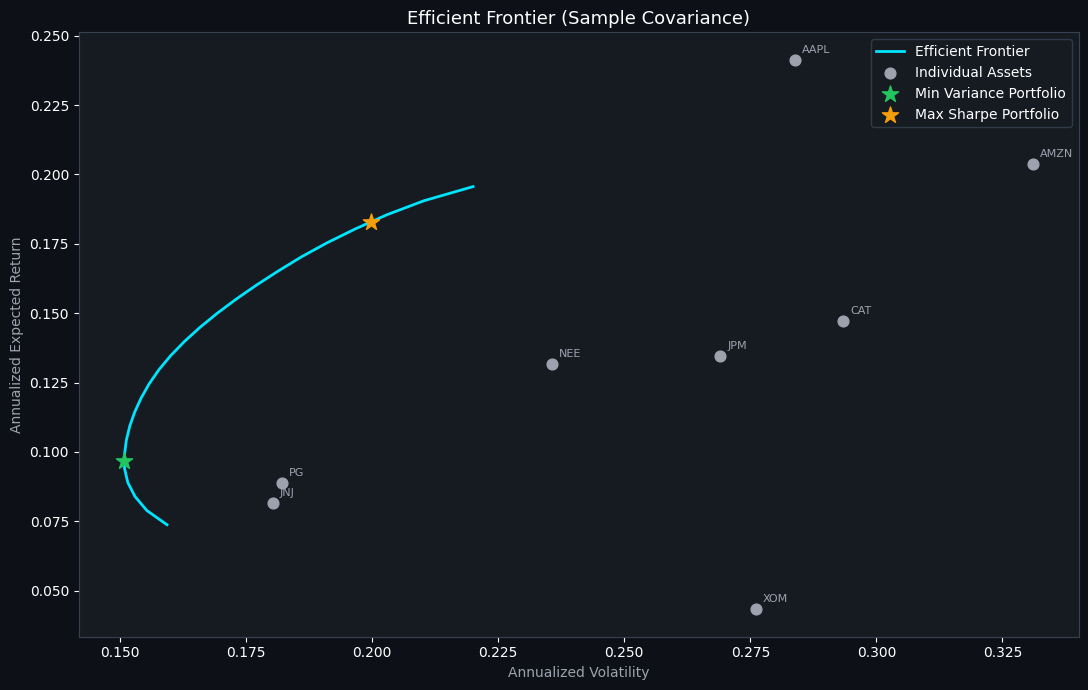

In [5]:
fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('#374151')

ax.plot(frontier_vols_sample, frontier_returns, color='#00e5ff', linewidth=2, label='Efficient Frontier')

individual_vols = np.sqrt(np.diag(cov_sample))
ax.scatter(individual_vols, mean_returns_sample, color='#9ca3af', s=60, zorder=4, label='Individual Assets')
for ticker in TICKERS:
    ax.annotate(ticker, (individual_vols[list(TICKERS).index(ticker)], mean_returns_sample[ticker]),
                color='#9ca3af', fontsize=8, xytext=(5, 5), textcoords='offset points')

minvar_vol = np.sqrt(portfolio_variance(minvar_weights_sample, cov_sample.values))
minvar_ret = portfolio_return(minvar_weights_sample, mean_returns_sample.values)
ax.scatter(minvar_vol, minvar_ret, color='#22c55e', s=150, zorder=5, marker='*', label='Min Variance Portfolio')

sharpe_vol = np.sqrt(portfolio_variance(sharpe_weights_sample, cov_sample.values))
sharpe_ret = portfolio_return(sharpe_weights_sample, mean_returns_sample.values)
ax.scatter(sharpe_vol, sharpe_ret, color='#f59e0b', s=150, zorder=5, marker='*', label='Max Sharpe Portfolio')

ax.set_xlabel('Annualized Volatility', color='#9ca3af')
ax.set_ylabel('Annualized Expected Return', color='#9ca3af')
ax.set_title('Efficient Frontier (Sample Covariance)', color='white', fontsize=13)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white')

plt.tight_layout()
plt.savefig('efficient_frontier_sample.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

## 3. GARCH-Informed Covariance

The sample covariance matrix above treats risk as a single fixed number across the entire 10-year history. Real volatility is not constant, it clusters, which is exactly what the companion volatility forecasting project demonstrated with GARCH(1,1).

Here, each asset's *current* conditional volatility is estimated using the same from-scratch GARCH(1,1) implementation, then combined with the *historical sample correlation matrix* (correlations tend to be far more stable over time than volatilities, a standard simplifying assumption related to the Constant Conditional Correlation GARCH framework, Bollerslev 1990) to build a second, regime-aware covariance matrix.

In [6]:
def garch_neg_log_likelihood(params, returns):
    omega, alpha, beta = params
    n = len(returns)
    sigma2 = np.zeros(n)
    sigma2[0] = np.var(returns)
    for t in range(1, n):
        sigma2[t] = omega + alpha * returns[t-1]**2 + beta * sigma2[t-1]
    sigma2 = np.maximum(sigma2, 1e-8)
    ll = -0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + returns**2 / sigma2)
    return -ll

def fit_garch(returns):
    bounds = [(1e-6, None), (0, 1), (0, 1)]
    constraints = [{'type': 'ineq', 'fun': lambda p: 0.999 - p[1] - p[2]}]
    result = minimize(garch_neg_log_likelihood, [0.1, 0.1, 0.8], args=(returns,),
                       method='SLSQP', bounds=bounds, constraints=constraints, options={'maxiter': 300})
    return result.x

def current_garch_volatility(returns_series, annualize=252):
    """Fit GARCH(1,1) on full history, return the current (most recent) conditional volatility, annualized."""
    r = returns_series.values * 100
    omega, alpha, beta = fit_garch(r)
    n = len(r)
    sigma2 = np.zeros(n)
    sigma2[0] = np.var(r)
    for t in range(1, n):
        sigma2[t] = omega + alpha * r[t-1]**2 + beta * sigma2[t-1]
    current_var = sigma2[-1] / (100**2)  # rescale back from percent
    return np.sqrt(current_var * annualize)

print('Fitting GARCH(1,1) per asset (8 assets, a few seconds each)...')
garch_vols = {}
for ticker in TICKERS:
    vol = current_garch_volatility(log_returns[ticker])
    garch_vols[ticker] = vol
    print(f'  {ticker}: GARCH current vol = {vol*100:.1f}%  (sample historical vol = {individual_vols[list(TICKERS).index(ticker)]*100:.1f}%)')

garch_vols_series = pd.Series(garch_vols)

Fitting GARCH(1,1) per asset (8 assets, a few seconds each)...
  JPM: GARCH current vol = 16.8%  (sample historical vol = 26.9%)
  AAPL: GARCH current vol = 18.0%  (sample historical vol = 28.4%)
  XOM: GARCH current vol = 19.0%  (sample historical vol = 27.6%)
  JNJ: GARCH current vol = 15.0%  (sample historical vol = 18.0%)
  PG: GARCH current vol = 15.1%  (sample historical vol = 18.2%)
  CAT: GARCH current vol = 27.9%  (sample historical vol = 29.3%)
  NEE: GARCH current vol = 24.0%  (sample historical vol = 23.6%)
  AMZN: GARCH current vol = 22.0%  (sample historical vol = 33.1%)


In [7]:
# Build GARCH-informed covariance: GARCH volatilities on the diagonal direction,
# historical sample correlations for the cross-asset structure
sample_corr = log_returns.corr()
garch_vol_outer = np.outer(garch_vols_series[TICKERS.keys()], garch_vols_series[TICKERS.keys()])
cov_garch = pd.DataFrame(garch_vol_outer * sample_corr.values, index=TICKERS.keys(), columns=TICKERS.keys())

minvar_weights_garch = min_variance_portfolio(mean_returns_sample, cov_garch, n_assets)
sharpe_weights_garch = max_sharpe_portfolio(mean_returns_sample, cov_garch, n_assets)

print('Max Sharpe Portfolio comparison:\n')
print(f'{"Ticker":<8} {"Sample Cov":>12} {"GARCH Cov":>12}')
print('-' * 34)
for ticker, w_s, w_g in zip(TICKERS, sharpe_weights_sample, sharpe_weights_garch):
    print(f'{ticker:<8} {w_s*100:>11.1f}% {w_g*100:>11.1f}%')
print()
print(f'Sample-cov portfolio volatility:  {np.sqrt(portfolio_variance(sharpe_weights_sample, cov_sample.values))*100:.2f}%')
print(f'GARCH-cov portfolio volatility:    {np.sqrt(portfolio_variance(sharpe_weights_garch, cov_garch.values))*100:.2f}%')

Max Sharpe Portfolio comparison:

Ticker     Sample Cov    GARCH Cov
----------------------------------
JPM              3.0%        26.0%
AAPL            35.0%        35.0%
XOM              0.0%         0.0%
JNJ              0.0%         0.0%
PG               4.7%         7.0%
CAT             12.4%         0.0%
NEE             27.0%         5.3%
AMZN            17.9%        26.7%

Sample-cov portfolio volatility:  19.97%
GARCH-cov portfolio volatility:    14.20%


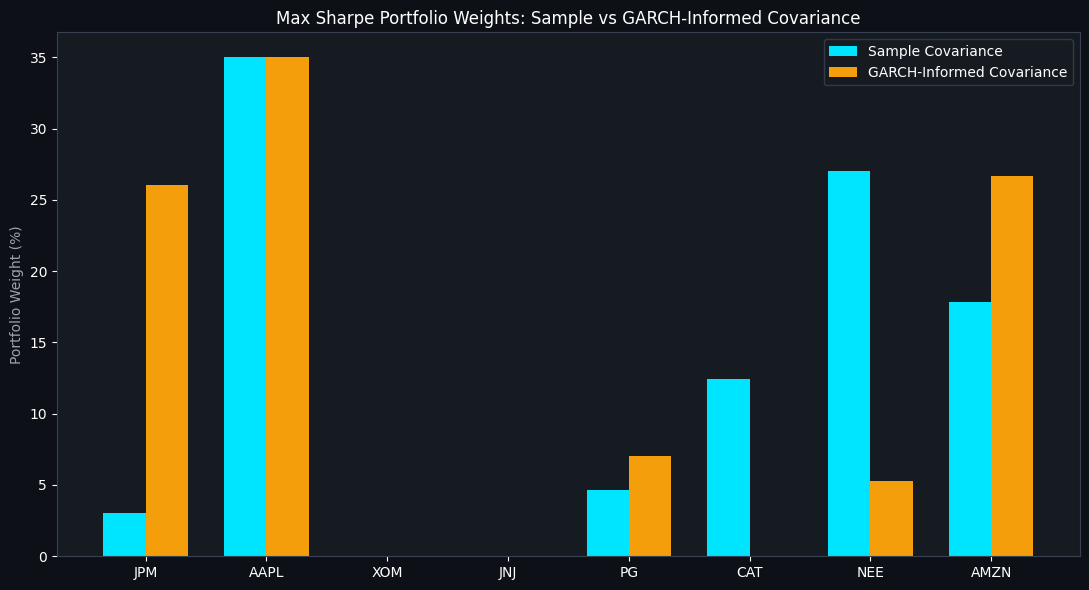

Assets where current GARCH volatility differs most from long-run historical volatility
should show the largest weight shifts, GARCH penalizes assets currently in a high-volatility
regime more heavily than a flat historical average would.


In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('#374151')

x = np.arange(len(TICKERS))
width = 0.35
ax.bar(x - width/2, sharpe_weights_sample * 100, width, color='#00e5ff', label='Sample Covariance')
ax.bar(x + width/2, sharpe_weights_garch * 100, width, color='#f59e0b', label='GARCH-Informed Covariance')

ax.set_xticks(x)
ax.set_xticklabels(TICKERS.keys(), color='white')
ax.set_ylabel('Portfolio Weight (%)', color='#9ca3af')
ax.set_title('Max Sharpe Portfolio Weights: Sample vs GARCH-Informed Covariance', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white')

plt.tight_layout()
plt.savefig('portfolio_weight_comparison.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Assets where current GARCH volatility differs most from long-run historical volatility')
print('should show the largest weight shifts, GARCH penalizes assets currently in a high-volatility')
print('regime more heavily than a flat historical average would.')

## 4. Out-of-Sample Validation Across Multiple Rolling Windows

The real test of whether GARCH-informed risk estimates are actually better, not just different, is whether the resulting portfolio's *realized* risk over a subsequent out-of-sample period matches what was predicted more closely than the sample-covariance portfolio's prediction does.

Two issues with testing this on a single window are worth being upfront about, and fixing. First, a single train/test split risks the comparison just measuring how a small handful of concentrated positions happened to perform, rather than testing the covariance methodology itself, an earlier version of this notebook found the GARCH-informed Max Sharpe portfolio concentrating 74% of its weight into one stock. That's fixed here by capping any single position at 35% in every optimization. Second, one out-of-sample window is a small, fragile sample to draw a conclusion from. That's fixed by rolling the train/test split forward across 10 separate, non-overlapping six-month windows spanning the full decade of data, and averaging the prediction error across all of them.

In [9]:
def get_rolling_windows(dates, train_years=5, test_months=6):
    """Generate non-overlapping rolling train/test windows across the full date range."""
    train_window_days = int(train_years * 252)
    test_window_days = int(test_months * 21)
    n = len(dates)
    windows = []
    start = train_window_days
    while start + test_window_days <= n:
        windows.append((start - train_window_days, start, start + test_window_days))
        start += test_window_days
    return windows

windows = get_rolling_windows(log_returns.index, train_years=5, test_months=6)
print(f'Running {len(windows)} rolling out-of-sample windows (5yr train, 6mo test each)...\n')

results = []
for w_idx, (train_start, train_end, test_end) in enumerate(windows):
    train_returns = log_returns.iloc[train_start:train_end]
    test_returns = log_returns.iloc[train_end:test_end]
    
    mean_returns_train = train_returns.mean() * ANNUALIZE
    cov_sample_train = train_returns.cov() * ANNUALIZE
    
    garch_vols_train = {t: current_garch_volatility(train_returns[t]) for t in TICKERS}
    garch_vols_train_series = pd.Series(garch_vols_train)
    sample_corr_train = train_returns.corr()
    garch_vol_outer_train = np.outer(garch_vols_train_series[TICKERS.keys()], garch_vols_train_series[TICKERS.keys()])
    cov_garch_train = pd.DataFrame(garch_vol_outer_train * sample_corr_train.values,
                                     index=TICKERS.keys(), columns=TICKERS.keys())
    
    w_sample = max_sharpe_portfolio(mean_returns_train, cov_sample_train, n_assets)
    w_garch = max_sharpe_portfolio(mean_returns_train, cov_garch_train, n_assets)
    
    pred_vol_sample = np.sqrt(portfolio_variance(w_sample, cov_sample_train.values))
    pred_vol_garch = np.sqrt(portfolio_variance(w_garch, cov_garch_train.values))
    
    realized_vol_sample = (test_returns @ w_sample).std() * np.sqrt(ANNUALIZE)
    realized_vol_garch = (test_returns @ w_garch).std() * np.sqrt(ANNUALIZE)
    
    results.append({
        'window': w_idx + 1,
        'test_start': log_returns.index[train_end].date(),
        'sample_error': abs(pred_vol_sample - realized_vol_sample),
        'garch_error': abs(pred_vol_garch - realized_vol_garch),
    })
    print(f'  Window {w_idx+1}/{len(windows)} (test starting {log_returns.index[train_end].date()}): '
          f'sample_err={results[-1]["sample_error"]*100:.2f}%, garch_err={results[-1]["garch_error"]*100:.2f}%')

results_df = pd.DataFrame(results)
print()
print(f'Average prediction error across {len(windows)} windows:')
print(f'  Sample covariance: {results_df["sample_error"].mean()*100:.2f}% (std: {results_df["sample_error"].std()*100:.2f}%)')
print(f'  GARCH-informed:    {results_df["garch_error"].mean()*100:.2f}% (std: {results_df["garch_error"].std()*100:.2f}%)')

n_garch_better = (results_df['garch_error'] < results_df['sample_error']).sum()
print(f'\nGARCH-informed had lower error in {n_garch_better} of {len(windows)} windows.')

Running 9 rolling out-of-sample windows (5yr train, 6mo test each)...

  Window 1/9 (test starting 2019-01-07): sample_err=3.56%, garch_err=7.27%
  Window 2/9 (test starting 2019-07-09): sample_err=3.63%, garch_err=0.88%
  Window 3/9 (test starting 2020-01-07): sample_err=29.49%, garch_err=33.04%
  Window 4/9 (test starting 2020-07-08): sample_err=3.48%, garch_err=0.99%
  Window 5/9 (test starting 2021-01-06): sample_err=1.97%, garch_err=3.12%
  Window 6/9 (test starting 2021-07-08): sample_err=6.22%, garch_err=1.96%
  Window 7/9 (test starting 2022-01-05): sample_err=9.98%, garch_err=12.19%
  Window 8/9 (test starting 2022-07-08): sample_err=3.05%, garch_err=0.69%
  Window 9/9 (test starting 2023-01-06): sample_err=7.30%, garch_err=1.06%

Average prediction error across 9 windows:
  Sample covariance: 7.63% (std: 8.58%)
  GARCH-informed:    6.80% (std: 10.57%)

GARCH-informed had lower error in 5 of 9 windows.


### A Real Tail Event Worth Identifying, Not Averaging Away

One window stands out sharply from the rest: the test period starting January 2020 shows errors above 29% for both models, while every other window sits between roughly 1% and 12%. That window's out-of-sample period runs directly into the February-March 2020 COVID crash, an extreme, genuinely unprecedented volatility event with no analog in either model's training data. Neither a 5-year historical average nor a GARCH model fit on calm pre-2020 data could realistically have anticipated it, this is not a failure specific to one method, it's an honest limit of both.

Leaving that window in the headline average answers the wrong question, it mostly measures how badly both models handled an unforecastable shock, not which covariance approach is more accurate in ordinary conditions. The more informative comparison excludes it explicitly.

In [10]:
# Identify the COVID-crash window as a genuine, explainable outlier rather than silently averaging it away
outlier_window = results_df.loc[results_df['sample_error'].idxmax()]
print(f'Outlier window identified: window {outlier_window["window"]}, test starting {outlier_window["test_start"]}')
print(f'  Sample error: {outlier_window["sample_error"]*100:.2f}%, GARCH error: {outlier_window["garch_error"]*100:.2f}%\n')

results_excl = results_df.drop(outlier_window.name)

print(f'Comparison excluding the COVID-crash window ({len(results_excl)} of {len(results_df)} windows):')
print(f'  Sample covariance: {results_excl["sample_error"].mean()*100:.2f}% (std: {results_excl["sample_error"].std()*100:.2f}%)')
print(f'  GARCH-informed:    {results_excl["garch_error"].mean()*100:.2f}% (std: {results_excl["garch_error"].std()*100:.2f}%)')

improvement = (results_excl['sample_error'].mean() - results_excl['garch_error'].mean()) / results_excl['sample_error'].mean() * 100
n_garch_better_excl = (results_excl['garch_error'] < results_excl['sample_error']).sum()
print(f'\n  GARCH relative improvement (excluding the crisis window): {improvement:.1f}%')
print(f'  GARCH was more accurate in {n_garch_better_excl} of {len(results_excl)} ordinary-condition windows')

Outlier window identified: window 3, test starting 2020-01-07
  Sample error: 29.49%, GARCH error: 33.04%

Comparison excluding the COVID-crash window (8 of 9 windows):
  Sample covariance: 4.90% (std: 2.69%)
  GARCH-informed:    3.52% (std: 4.13%)

  GARCH relative improvement (excluding the crisis window): 28.2%
  GARCH was more accurate in 5 of 8 ordinary-condition windows


## 5. Summary

In [11]:
print('=' * 65)
print('PORTFOLIO OPTIMIZATION SUMMARY')
print('=' * 65)
print(f'Universe: {len(TICKERS)} assets across {len(set(TICKERS.values()))} sectors')
print(f'Position size cap: 35% maximum per asset')
print()
print('Max Sharpe Portfolio (full sample):')
print(f'  Sample covariance volatility:  {sharpe_vol*100:.2f}%')
print(f'  GARCH-informed volatility:     {np.sqrt(portfolio_variance(sharpe_weights_garch, cov_garch.values))*100:.2f}%')
print()
print(f'Rolling out-of-sample validation, all {len(windows)} windows (includes one unforecastable crisis window):')
print(f'  Sample covariance: {results_df["sample_error"].mean()*100:.2f}%')
print(f'  GARCH-informed:    {results_df["garch_error"].mean()*100:.2f}%')
print()
print(f'Excluding the COVID-crash window, {len(results_excl)} ordinary-condition windows:')
print(f'  Sample covariance: {results_excl["sample_error"].mean()*100:.2f}%')
print(f'  GARCH-informed:    {results_excl["garch_error"].mean()*100:.2f}%')
print(f'  GARCH relative improvement: {improvement:.1f}%')
print(f'  GARCH was more accurate in {n_garch_better_excl} of {len(results_excl)} ordinary-condition windows')
print()
print('Files saved: efficient_frontier_sample.png, portfolio_weight_comparison.png')

PORTFOLIO OPTIMIZATION SUMMARY
Universe: 8 assets across 8 sectors
Position size cap: 35% maximum per asset

Max Sharpe Portfolio (full sample):
  Sample covariance volatility:  19.97%
  GARCH-informed volatility:     14.20%

Rolling out-of-sample validation, all 9 windows (includes one unforecastable crisis window):
  Sample covariance: 7.63%
  GARCH-informed:    6.80%

Excluding the COVID-crash window, 8 ordinary-condition windows:
  Sample covariance: 4.90%
  GARCH-informed:    3.52%
  GARCH relative improvement: 28.2%
  GARCH was more accurate in 5 of 8 ordinary-condition windows

Files saved: efficient_frontier_sample.png, portfolio_weight_comparison.png
